Paquetes necesarios

In [45]:
import csv
from collections import Counter, deque

import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
)

**TAREA 1:** Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas? Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

En primera instancia, se deberá cargar la imagen ideal de las monedas. 

(938, 473, 3)


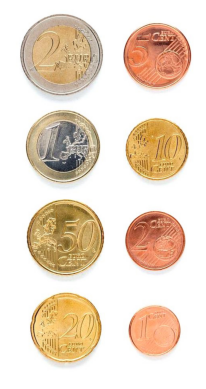

In [46]:
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
print(img.shape)
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.axis("off")
plt.imshow(img_rgb) 
plt.show()

Una vez completada la carga, se trabajará sobre esta para detectar los valores de las monedas. Para ello, será esencial definir un diccionario que establecerá una relación entre el nombre que recibirá la moneda (clave) y el tamaño de la misma (valor), así como otro diccionario con la misma clave pero que en esta ocasión lo relaciona con el valor de la moneda.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


Valor total: 3.88 €


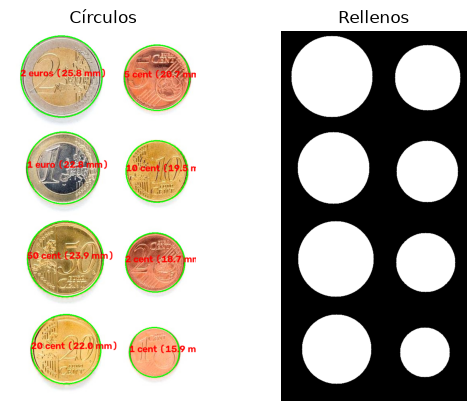

In [47]:
MONEDAS = {
    "2 euros": 25.75,
    "1 euro": 23.25,
    "50 cent": 24.25,
    "20 cent": 22.25,
    "10 cent": 19.75,
    "5 cent": 21.25,
    "2 cent": 18.75,
    "1 cent": 16.25,
}

VALORES = {
    "2 euros": 2.00,
    "1 euro": 1.00,
    "50 cent": 0.50,
    "20 cent": 0.20,
    "10 cent": 0.10,
    "5 cent": 0.05,
    "2 cent": 0.02,
    "1 cent": 0.01,
}

# Moneda de referencia para calibrar (2 euros)
DIAM_REF = 25.75

# Índice de la moneda de referencia dentro de las detectadas
IDX_REF = 0

# Error máximo admitido para clasificar
TOLERANCIA = 0.6

# Conversión a gris
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suaviza imagen (elimina altas frecuencias)
pimg = cv2.medianBlur(gris, 7)

# Localiza Círculos
circ = cv2.HoughCircles(
    pimg,  # imagen
    cv2.HOUGH_GRADIENT,  # tipo de detección
    1,
    100,  # distancia mínima entre círculos
    param1=100,  # valor del gradiente
    param2=50,  # umbral acumulador
    minRadius=50,  # radio mínimo
    maxRadius=150,  # radio máximo
)

# Binariza (Otsu) sobre la imagen suavizada: monedas en blanco sobre fondo negro
_, bina = cv2.threshold(pimg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# Si el borde de la imagen es blanco, invierte
if bina[0, :].mean() > 127:
    bina = cv2.bitwise_not(bina)

# Localiza contornos externos (el anillo interior de 1 € y 2 € no cuenta)
contornos, _ = cv2.findContours(bina, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Dibuja sobre entrada e imagen vacía
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_cont = np.zeros(img_rgb.shape)

# Inicialización del valor total monedas detectadas
total = 0.0

if circ is not None:
    # Refinamiento: Hough localiza, el contorno exterior da el radio real
    det_monedas = []

    for x_coor, y_coor, det_radio in circ[0]:
        for c in contornos:
            if (len(c) >= 5 and cv2.pointPolygonTest(c, (float(x_coor), float(y_coor)), False) >= 0):
                (x_coor, y_coor), (eje_a, eje_b), _ = cv2.fitEllipse(c)
                det_radio = (eje_a + eje_b) / 4
                # Si no se detecta el contorno, se mantiene el círculo de Hough
                break
        det_monedas.append((x_coor, y_coor, det_radio))

    # Calibración: píxeles por milímetro a partir de la moneda de referencia
    diam_ref_px = 2 * max(m[2] for m in det_monedas)
    px_por_mm = diam_ref_px / DIAM_REF

    for x_coor, y_coor, det_radio in det_monedas:
        diam_mm = 2 * det_radio / px_por_mm
        nombre, diam_real = min(MONEDAS.items(), key=lambda m: abs(m[1] - diam_mm))

        if abs(diam_real - diam_mm) > TOLERANCIA:
            nombre = "?"
        else:
            total += VALORES[nombre]    

        cv2.circle(img_rgb, (int(x_coor), int(y_coor)), int(det_radio), (0, 255, 0), 2)
        
        # Texto sobre la moneda detectada
        cv2.putText(
            img_rgb,
            f"{nombre} ({diam_mm:.1f} mm)",
            (int(x_coor - det_radio), int(y_coor)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 0, 0),
            2,
        )

        cv2.circle(
            img_cont, (int(x_coor), int(y_coor)), int(det_radio), (255, 255, 255), -1
        )

# Se imprime el valor total de las monedas detectadas
print(f"Valor total: {total:.2f} €")

# Muestra resultado
plt.subplot(121)
plt.axis("off")
plt.imshow(img_rgb)
plt.title("Círculos")

plt.subplot(122)
plt.axis("off")
plt.imshow(img_cont)
plt.title("Rellenos")

plt.show()

Una vez realizada la detección con la situación ideal, se planteará una solución para la situación de las monedas captada con la cámara externa. En esta parte, se hará clic sobre una moneda concreta (previamente establecida en el código) para establecer la relación entre píxeles y milímetros. 
Para ello, se declarará una función para detectar los clics en la escena.

In [48]:
def on_mouse(evento, x, y, flags, param):
    global clic
    if evento == cv2.EVENT_LBUTTONDOWN:
        clic = (x, y)

Previo al comienzo de la detección, cabe destacar que las distintas pruebas de detección de las monedas se han realizado en un entorno en el que la mesa era de madera y la iluminación variaba bastante. Por ello, y como se pretende usar Otsu para el umbralizado, para las presentes pruebas de detección se ha usado como base para colocar las monedas un folio, lo cual ha resultado en la definición de la presente función. 

In [49]:
def segmentar_folio(img):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    pimg = cv2.medianBlur(gris, 7)
    _, bina = cv2.threshold(pimg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # El folio es la mayor región blanca: se rellena para delimitar la zona de trabajo
    cont_f, _ = cv2.findContours(bina, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cont_f:
        return None
    folio = np.zeros_like(bina)
    cv2.drawContours(folio, [max(cont_f, key=cv2.contourArea)], -1, 255, -1)

    # Monedas = dentro del folio y no blancas
    return cv2.bitwise_and(folio, cv2.bitwise_not(bina))

Realizada la declaración de la anterior función, se define una función para la detección de las monedas. En esta, se integra la segmentación realizada por la función anterior con análisis geométrico y del color. De esta forma, se conseguirá detectar aquellos objetos con forma y color propios de una moneda.

In [50]:
def detectar(img):
    # Imagen en HSV para la discriminación por color
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    bina = segmentar_folio(img)
    if bina is None:
        return []

    # Limpieza común
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    bina = cv2.morphologyEx(bina, cv2.MORPH_OPEN, k)
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))  # cierra el centro plateado del 1 € y 2 €
    bina = cv2.morphologyEx(bina, cv2.MORPH_CLOSE, k2)

    # Localiza contornos externos
    contornos, _ = cv2.findContours(bina, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lado = min(img.shape[:2])
    r_min, r_max = 0.015 * lado, 0.15 * lado  # radio como fracción del frame

    det_monedas = []
    for c in contornos:
        if len(c) < 5:
            continue
        area = cv2.contourArea(c)
        per = cv2.arcLength(c, True)
        if per == 0 or area == 0:
            continue
        circularidad = 4 * np.pi * area / per**2

        (x_coor, y_coor), (eje_a, eje_b), _ = cv2.fitEllipse(c)
        if min(eje_a, eje_b) == 0:
            continue
        det_radio = (eje_a + eje_b) / 4

        if (r_min <= det_radio <= r_max and circularidad > 0.8
                and min(eje_a, eje_b) / max(eje_a, eje_b) > 0.85):
            fam = familia_color(hsv, x_coor, y_coor, det_radio)
            if fam is not None:
                det_monedas.append((x_coor, y_coor, det_radio, fam))
    return det_monedas

En la función de detección se mencionó que se realiza análisis cromático (color de las monedas). Esto es posible gracias a la función _familia_color()_, la cual analiza el color de las posibles monedas de manera complementaria al tamaño de estas.

Para ello, previamente se definirán unos umbrales a tener en cuenta en este análsis cromático.

In [51]:
# Color (HSV de OpenCV: H 0-179, S 0-255)
S_MIN = 40 # saturación mínima: por debajo es gris/blanco/negro (no metal cálido)
H_COBRE_MAX = 20 # H por debajo => cobre (rojizo), por encima => oro (amarillento)
H_FRIO_MIN, H_FRIO_MAX = 75, 150 # verdes/azules/violetas: no son monedas
UMBRAL_BI_H = 8 # diferencia de H centro-corona para considerar bimetálica
UMBRAL_BI_S = 50 # diferencia de S centro-corona para considerar bimetálica

Así como la relación entre las monedas y la familia cromática a la que pertenecen

In [52]:
FAMILIA = {
    "1 cent": "cobre", 
    "2 cent": "cobre", 
    "5 cent": "cobre",
    "10 cent": "oro", 
    "20 cent": "oro", 
    "50 cent": "oro",
    "1 euro": "bi", 
    "2 euros": "bi",
}

In [53]:
def familia_color(hsv, x_coor, y_coor, det_radio):
    """Devuelve 'cobre', 'oro', 'bi', '?' (color no fiable) o None si es color frío."""
    x, y, r = int(x_coor), int(y_coor), int(det_radio)
    x0, y0 = max(x - r, 0), max(y - r, 0)
    roi = hsv[y0:y + r, x0:x + r]
    if roi.size == 0:
        return None

    yy, xx = np.ogrid[y0:y0 + roi.shape[0], x0:x0 + roi.shape[1]]
    dist = np.hypot(xx - x_coor, yy - y_coor)
    util = (roi[..., 2] > 60) & (roi[..., 2] < 240)   # sin sombras ni brillos especulares
    centro = (dist <= 0.4 * det_radio) & util
    # Corona pegada al borde: evita la frontera plata/oro del 1 € y 2 €
    corona = (dist >= 0.82 * det_radio) & (dist <= 0.94 * det_radio) & util
    if centro.sum() < 10 or corona.sum() < 10:
        return "?"

    h_c, s_c, _ = np.median(roi[centro], axis=0)
    h_k, s_k, _ = np.median(roi[corona], axis=0)

    # Color poco saturado: no es fiable, que decida el tamaño
    if s_c < S_MIN and s_k < S_MIN:
        return "?"

    # Descarta colores fríos (azules, verdes...) cuando están saturados
    for h, s in ((h_c, s_c), (h_k, s_k)):
        if s >= S_MIN and H_FRIO_MIN <= h <= H_FRIO_MAX:
            return None

    # Bimetálica: cambio de tono con color suficiente en ambas zonas, o gran cambio de saturación
    dh = min(abs(h_c - h_k), 180 - abs(h_c - h_k))
    if (dh > UMBRAL_BI_H and min(s_c, s_k) > S_MIN) or abs(s_c - s_k) > UMBRAL_BI_S:
        return "bi"

    return "cobre" if h_k < H_COBRE_MAX else "oro"

Para que la detección de las monedas sea más estable, se han definido funciones auxiliares que ayudarán al procesamiento de los fotogramas. De esta forma, se guarda un registro de las monedas que se han detectado ya anteriormente con las que se han detectado en el fotograma actual, consiguiendo un dibujado de los círculos sobre las posibles monedas más estable.

No obstante, antes de la definición de las mismas, se han definido variables que son imprescindibles para la correcta ejecución de estas funciones.

In [54]:
N_HIST = 15 # Se establecen los frames que se recuerdan por moneda
MIN_HIST = 5 # Se establecen los frames mínimos antes de mostrar una decisión
MAX_PERDIDOS = 10 # Se establecen los frames sin ver una moneda antes de olvidarla
tracks = [] # Se almacena el seguimiento de las monedas detectadas

Las funciones _actualizar_tracks()_ y _estado_track()_ asocian las monedas detectadas en cada fotograma con los tracks existentes (y eliminando aquellos que llevan varios fotogramas sin detectarse) y calculan la mediana de los radios almacenados para determinar la familia cromática más probable entre las detecciones de los fotogramas, respectivamente.

In [55]:
def actualizar_tracks(det_monedas):
    """Asocia detecciones con tracks por cercanía de centros y acumula historial."""
    global tracks
    for t in tracks:
        t["visto"] = False
    usados = set()

    for x, y, r, fam in det_monedas:
        mejor, mejor_d = None, 1e9
        for i, t in enumerate(tracks):
            if i in usados:
                continue
            d = np.hypot(t["x"] - x, t["y"] - y)
            if d < mejor_d and d < max(t["r"], r):
                mejor, mejor_d = i, d
        if mejor is None:
            tracks.append({"x": x, "y": y, "r": r,
                           "radios": deque([r], maxlen=N_HIST),
                           "fams": deque([fam], maxlen=N_HIST),
                           "visto": True, "perdidos": 0})
            usados.add(len(tracks) - 1)
        else:
            t = tracks[mejor]
            t["x"], t["y"], t["r"] = x, y, r
            t["radios"].append(r)
            t["fams"].append(fam)
            t["visto"], t["perdidos"] = True, 0
            usados.add(mejor)

    for t in tracks:
        if not t["visto"]:
            t["perdidos"] += 1
    tracks = [t for t in tracks if t["perdidos"] <= MAX_PERDIDOS]


def estado_track(t):
    """Radio mediano y familia más votada (ignorando '?' si hay otra)."""
    r_med = float(np.median(t["radios"]))
    votos = Counter(f for f in t["fams"] if f != "?") or Counter(t["fams"])
    return r_med, votos.most_common(1)[0][0]

In [66]:
REF = "1 euro" # Se establece la moneda de referencia 
TOLERANCIA = 0.8   # Se aumenta la tolerancia (mm) respecto a la situación ideal

px_por_mm = None
clic = None

vid = cv2.VideoCapture(2)
vid.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
vid.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

cv2.namedWindow("Deteccion de monedas")
cv2.setMouseCallback("Deteccion de monedas", on_mouse)

while True:
    ret, frame = vid.read()

    if ret:
        img = cv2.flip(frame, 1)

        det_monedas = detectar(img)

        # Calibración: píxeles por milímetro a partir de la moneda de referencia clicada
        if clic and det_monedas:
            x_ref, y_ref, r_ref, _ = min(
                det_monedas, key=lambda m: np.hypot(m[0] - clic[0], m[1] - clic[1])
            )
            if np.hypot(x_ref - clic[0], y_ref - clic[1]) <= r_ref:
                diam_ref_px = 2 * r_ref
                px_por_mm = diam_ref_px / MONEDAS[REF]
        clic = None

        # Seguimiento temporal: acumula historial de radio y familia por moneda
        actualizar_tracks(det_monedas)

        if px_por_mm:
            # Inicialización del valor total de monedas detectadas
            total = 0.0

            for t in tracks:
                if not t["visto"] or len(t["radios"]) < MIN_HIST:
                    continue
                r_med, fam = estado_track(t)
                x_coor, y_coor, det_radio = t["x"], t["y"], r_med
                diam_mm = 2 * det_radio / px_por_mm

                # 1º el tamaño: candidatas compatibles por diámetro
                candidatas = {n: d for n, d in MONEDAS.items() if abs(d - diam_mm) <= TOLERANCIA}

                # 2º el color solo desempata si hay más de una candidata
                if len(candidatas) > 1 and fam != "?":
                    por_color = {n: d for n, d in candidatas.items() if FAMILIA[n] == fam}
                    if por_color:
                        candidatas = por_color

                if candidatas:
                    nombre, diam_real = min(candidatas.items(), key=lambda m: abs(m[1] - diam_mm))
                    total += VALORES[nombre]
                    color = (0, 255, 0)
                else:
                    nombre = "?"
                    color = (0, 0, 255)

                cv2.circle(img, (int(x_coor), int(y_coor)), int(det_radio), color, 2)

                # Texto sobre la moneda detectada
                cv2.putText(
                    img,
                    f"{nombre} ({diam_mm:.1f} mm)",
                    (int(x_coor - det_radio), int(y_coor)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 0, 0),
                    2,
                )

            cv2.putText(img, f"Valor total: {total:.2f} EUR", (10, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        else:
            for x_coor, y_coor, det_radio, fam in det_monedas:
                cv2.circle(img, (int(x_coor), int(y_coor)), int(det_radio), (0, 255, 255), 2)
            cv2.putText(img, f"Clic sobre una moneda de {REF}", (10, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        cv2.putText(img, "r recalibrar | ESC salir",
                    (10, img.shape[0] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        cv2.imshow("Deteccion de monedas", img)

    tecla = cv2.waitKey(20) & 0xFF
    if tecla == 27:  # ESC
        break
    elif tecla == ord("r"):  # Recalibra con la moneda de referencia
        px_por_mm = None
        tracks = []

vid.release()
cv2.destroyAllWindows()

**TAREA 2:** La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo.

En primer lugar, se procederá a la carga de las imágenes de fragmentos, pellets y alquitrán.

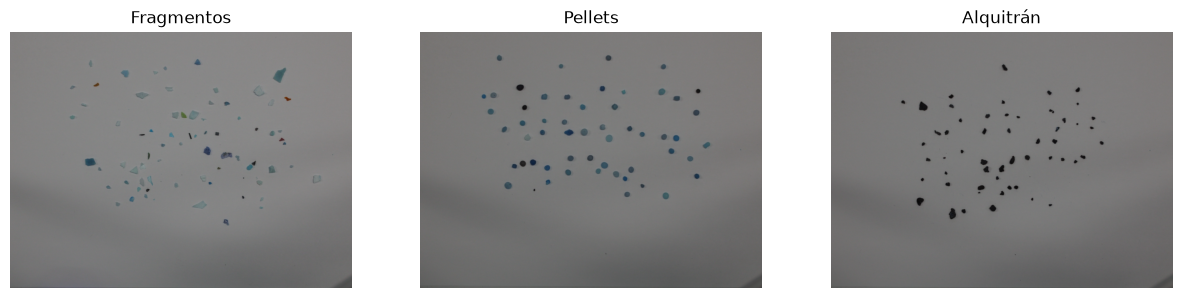

In [57]:
# Se cargan las imágenes
frag = cv2.imread("./referencia/fragment-03-olympus-10-01-2020.JPG")
pellet = cv2.imread("./referencia/pellet-03-olympus-10-01-2020.JPG")
tar = cv2.imread("./referencia/tar-03-olympus-10-01-2020.JPG")

# Mostramos
plt.figure(figsize=(15, 6))
plt.subplot(131)
plt.axis("off")
plt.imshow(frag)
plt.title("Fragmentos")

plt.subplot(132)
plt.axis("off")
plt.imshow(pellet)
plt.title("Pellets")

plt.subplot(133)
plt.axis("off")
plt.imshow(tar)
plt.title("Alquitrán")
plt.savefig("./resultados/carga_imagenes.jpg", bbox_inches="tight", dpi=300)
plt.show()

Acto seguido, se procede al recorte de las imágenes.

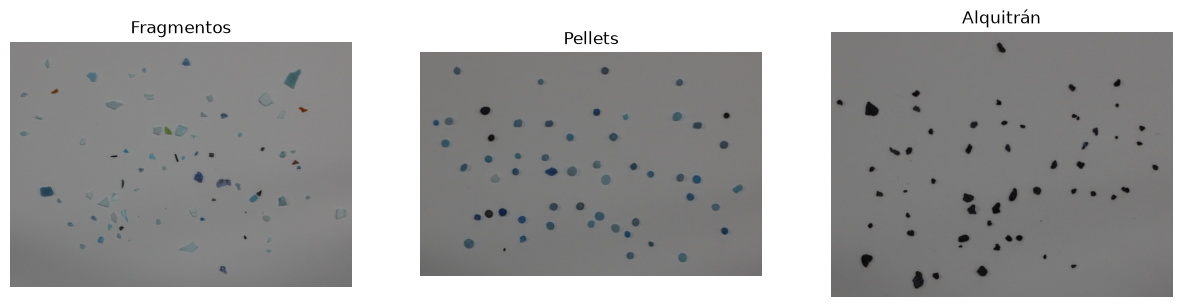

In [58]:
# Recortes de las imágenes con las que trabajamos
frag_crop = frag[(slice(200, 2750), slice(700, 4250))]
pellet_crop = pellet[(slice(175, 2400), slice(700, 4100))]
tar_crop = tar[(slice(350, 2600), slice(900, 3800))]

# Mostramos
plt.figure(figsize=(15, 6))
plt.subplot(131)
plt.axis("off")
plt.imshow(frag_crop)
plt.title("Fragmentos")

plt.subplot(132)
plt.axis("off")
plt.imshow(pellet_crop)
plt.title("Pellets")

plt.subplot(133)
plt.axis("off")
plt.imshow(tar_crop)
plt.title("Alquitrán")
plt.savefig("./resultados/recortes.jpg", bbox_inches="tight", dpi=300)
plt.show()

Con las imágenes una vez recortadas, se procecerá a la segmentación de las mismas. Para ello, se procederá a definir la función contornos: a partir de la imagen RGB, devuelve los contornos y la máscara binaria.

In [59]:
def contornos(img_rgb, escala=1.0):
    # Gris
    img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    img = cv2.resize(img, None, fx=escala, fy=escala)

    # Blur
    img = cv2.GaussianBlur(img, (5, 5), 0)

    # Resta de fondo
    fondo = cv2.resize(cv2.medianBlur(cv2.resize(img, (400, 300)), 31), img.shape[::-1])

    # Umbral
    _, bw = cv2.threshold(cv2.absdiff(img, fondo), 8, 255, cv2.THRESH_BINARY)

    # Búsqueda de contornos
    cs, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in cs if cv2.contourArea(c) > 40], bw

Escala de reducción:  0.2795138888888889
Partículas:  71 55 54


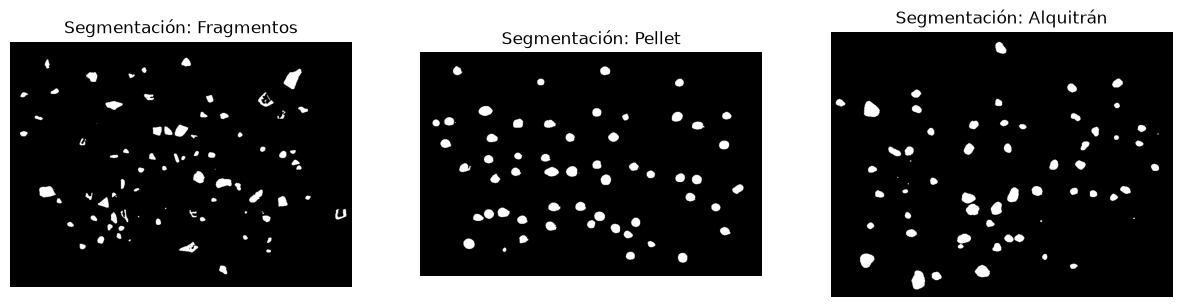

In [60]:
# Las imágenes de referencia se reducen a una escala parecida a la del test
escala = 1288 / frag.shape[1]
print("Escala de reducción: ", escala)

cs_frag, bw_frag = contornos(frag_crop, escala)
cs_pellet, bw_pellet = contornos(pellet_crop, escala)
cs_tar, bw_tar = contornos(tar_crop, escala)
print("Partículas: ", len(cs_frag), len(cs_pellet), len(cs_tar))

plt.figure(figsize=(15, 6))
for i, (bw, t) in enumerate(
    [(bw_frag, "Fragmentos"), (bw_pellet, "Pellet"), (bw_tar, "Alquitrán")]
):
    plt.subplot(1, 3, i + 1)
    plt.axis("off")
    plt.imshow(bw, cmap="gray")
    plt.title("Segmentación: " + t)
plt.savefig("./resultados/segmentacion_entrenamiento.jpg", bbox_inches="tight", dpi=300)
plt.show()

Para la extracción de las características geométricas de cada partícula, se procederá a la definición de otra función: caracteristicas(). Con esta función, se extraen las características que definen a cada partícula y se le asigna la etiqueta correspondiente

In [61]:
def caracteristicas(c):
    area, per = cv2.contourArea(c), cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    (_, _), (e1, e2), _ = cv2.fitEllipse(c)
    return [
        per**2 / area,              # compacidad
        area / (w * h),             # área / contenedor
        max(w, h) / min(w, h),      # ancho / alto
        min(e1, e2) / max(e1, e2),  # ejes de la elipse
    ]


UMBRAL_TAR = 0.6

X, y = [], []
for cs, clase in [(cs_frag, "FRA"), (cs_pellet, "PEL"), (cs_tar, "TAR")]:
    for c in cs:
        X.append(caracteristicas(c))
        y.append(clase)
X, y = np.array(X), np.array(y)

Se definirá una medida de oscuridad para identificar las posibles partículas de alquitrán. Para los fragmentos y pellets, se procederá al normalizado de las características con estadísticas de entrenamiento.

In [62]:
# Se define la característica oscuridad a parte, porque es una característica típica del alquitrán, que es más fácil de identificar
def oscuridad(img, c):
    mask = np.zeros(img.shape[:2], np.uint8)
    cv2.drawContours(mask, [c], -1, 255, -1)
    fuera = cv2.bitwise_not(cv2.dilate(mask, np.ones((15, 15), np.uint8)))
    dentro = img[mask > 0].astype(float)
    gris = dentro.mean(1)
    nucleo = dentro[gris <= np.percentile(gris, 30)].mean(0)
    return (nucleo / img[fuera > 0].mean(0)).mean()  # 1 = como el fondo, 0 = negro


clases = ["FRA", "PEL"]
x2, y2 = X[y != "TAR"], y[y != "TAR"]
mu, sd = x2.mean(0), x2.std(0)
medias = [((x2[y2 == k] - mu) / sd).mean(0) for k in clases]


def predice(img, c):
    if oscuridad(img, c) < UMBRAL_TAR:
        return "TAR"
    f = (np.array(caracteristicas(c)) - mu) / sd
    return clases[np.argmin([np.linalg.norm(f - m) for m in medias])]

Se cargará la imagen de test [MPs_test.jpg](./test/MPs_test.jpg) y se aplica la función de segmentación utilizada con las referencias.

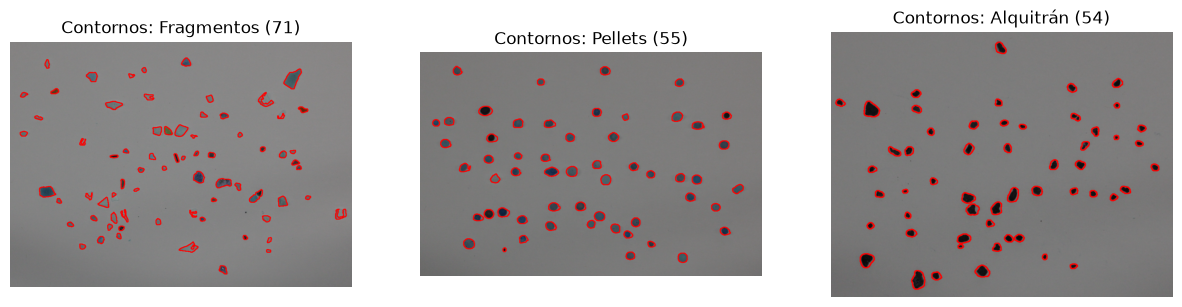

In [63]:
test = cv2.cvtColor(cv2.imread("./test/MPs_test.jpg"), cv2.COLOR_BGR2RGB)
cs_test, bw_test = contornos(test)
plt.figure(figsize=(15, 6))
for i, (crop, cs, t) in enumerate(
    [
        (frag_crop, cs_frag, "Fragmentos"),
        (pellet_crop, cs_pellet, "Pellets"),
        (tar_crop, cs_tar, "Alquitrán"),
    ]
):
    vis = cv2.resize(crop, None, fx=escala, fy=escala)  # misma escala que los contornos
    cv2.drawContours(vis, cs, -1, (255, 0, 0), 2)
    plt.subplot(1, 3, i + 1)
    plt.axis("off")
    plt.imshow(vis)
    plt.title(f"Contornos: {t} ({len(cs)})")
plt.savefig("./resultados/segmentacion_entrenamiento.jpg", bbox_inches="tight", dpi=300)
plt.show()

A continuación, se leerá del archivo CSV las etiquetas reales y las coordenadas de las cajas anotadas para realizar la predicción.

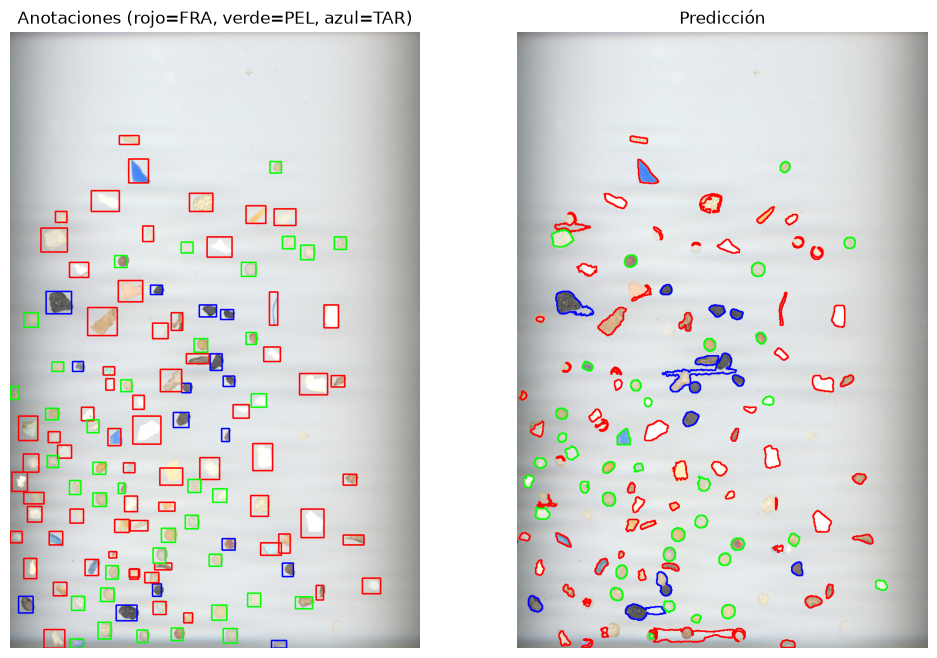

In [64]:
anot = []
with open("./test/MPs_test_bbs.csv", newline="") as file:
    for fila in csv.DictReader(file):
        anot.append(
            (
                fila["label"],
                int(fila["x_min"]),
                int(fila["y_min"]),
                int(fila["x_max"]),
                int(fila["y_max"]),
            )
        )
colores = {"FRA": (255, 0, 0), "PEL": (0, 255, 0), "TAR": (0, 0, 255)}
img_anot, img_pred = test.copy(), test.copy()
real, pred = [], []
for etiqueta, x_min, y_min, x_max, y_max in anot:
    centro = ((x_min + x_max) / 2, (y_min + y_max) / 2)
    c = max(cs_test, key=lambda c: cv2.pointPolygonTest(c, centro, True))
    p = predice(test, c)
    real.append(etiqueta)
    pred.append(p)
    cv2.rectangle(img_anot, (x_min, y_min), (x_max, y_max), colores[etiqueta], 2)
    cv2.drawContours(img_pred, [c], -1, colores[p], 2)

plt.figure(figsize=(12, 8))
plt.subplot(121)
plt.axis("off")
plt.imshow(img_anot)
plt.title("Anotaciones (rojo=FRA, verde=PEL, azul=TAR)")
plt.subplot(122)
plt.axis("off")
plt.imshow(img_pred)
plt.title("Predicción")
plt.savefig("./resultados/prediccion.jpg", bbox_inches="tight", dpi=300)
plt.show()

Finalmente, se calculan la tasa de acierto y la precisión ponderada comparando las etiquetas reales con las predicciones. Asimismo, se genera la matriz de confusión para resumir los aciertos y las confusiones entre las 3 clases.


MÉTRICAS:
Tasa de acierto  = 0.692
Precisión = 0.692


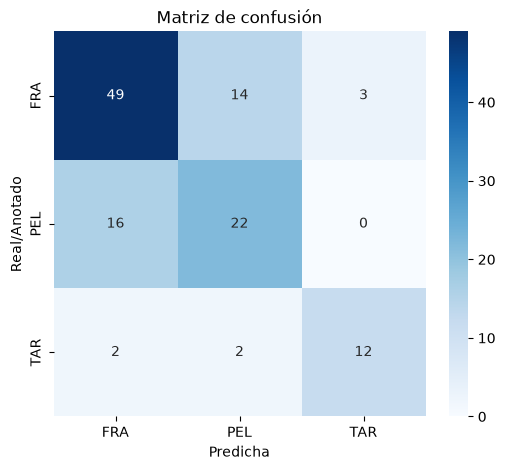

In [65]:
accuracy = accuracy_score(real, pred)
precision = precision_score(real, pred, average="weighted", zero_division=0)

print("\nMÉTRICAS:")
print(f"Tasa de acierto  = {accuracy:.3f}")
print(f"Precisión = {precision:.3f}")

clases = ["FRA", "PEL", "TAR"] # Se define TAR antes de hacer la matriz de confusión
cm = confusion_matrix(real, pred, labels=clases)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases,
)
plt.xlabel("Predicha")
plt.ylabel("Real/Anotado")
plt.title("Matriz de confusión")
plt.savefig("./resultados/matriz_confusion.jpg", bbox_inches="tight", dpi=300)
plt.show()